# Alquiler — 02 Limpieza y preparación

Convierte los hallazgos de `01_EDA.ipynb` en decisiones explícitas y reproducibles
para la regresión lineal posterior de `monthly_rent_rub`. 

## 0. Entorno

Correr con el kernel **(.venv)**. Si falta el entorno:

```
source .venv/bin/activate
pip install -r requirements.txt
```

In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"
SEED = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__)
print("DATA_DIR:", DATA_DIR.resolve(), "| existe:", DATA_DIR.exists())

pandas 3.0.6 | numpy 2.5.4
DATA_DIR: /Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/data | existe: True


### Carga y contrato de entrada

El crudo no se toca: se lee, se verifica su forma y todo cambio ocurre en memoria hasta el guardado de #9.

In [39]:
rentals = pd.read_csv(DATA_DIR / "rentals.csv")
assert rentals.shape == (20000, 22), f"forma inesperada: {rentals.shape}"
print(f"{len(rentals):,} filas x {rentals.shape[1]} columnas")
display(rentals.head(3))
display(rentals.dtypes.astype(str).rename("dtype").to_frame())

20,000 filas x 22 columnas


,id,date_posted,district,okrug,lat,lon,total_area,rooms,floor,total_floors,building_year,building_type,renovation,furnished,pets_allowed,deposit_months,metro_station,metro_line,metro_distance_min,to_center_km,monthly_rent_rub,rent_per_sqm
0,R000001,2025-01-16,Nagatinsky Zaton,YuAO,55.70058,37.69344,34.7,1,5,9,1958,brick,cosmetic,False,True,1,Ugreshskaya,MCC,28,7.47,26200,756
1,R000002,2022-11-12,Chertanovo Severnoye,YuAO,55.64717,37.61690,53.4,1,10,12,2010,monolith,cosmetic,True,False,1,Kuznetsky Most,Tagansko-Krasnopresnenskaya,152,11.87,37200,696
2,R000003,2026-03-06,Savyolovsky,SAO,55.78584,37.57104,69.9,2,15,22,2009,monolith,euro,True,False,1,Rizhskaya,Kaluzhsko-Rizhskaya,43,4.72,96700,1384


,dtype
id,str
date_posted,str
district,str
okrug,str
lat,float64
lon,float64
total_area,float64
rooms,int64
floor,int64
total_floors,int64


## 1. Duplicados: exactos vs. repeticiones legítimas

Un aviso republicado (mismo inmueble, otra fecha) es un registro legítimo;
una fila idéntica en todo o un `id` repetido es un error de carga. Se chequean
las cuatro variantes antes de decidir: si todas dan 0, no hay nada que borrar
y el chequeo queda como evidencia.

In [40]:
sin_id = [c for c in rentals.columns if c != "id"]
clave_negocio = ["district", "total_area", "rooms", TARGET, "date_posted"]
dup = pd.Series({
    "exactos (todas las columnas)": int(rentals.duplicated().sum()),
    "sin id (mismo aviso, otro id)": int(rentals.duplicated(subset=sin_id).sum()),
    "id repetido": int(rentals.duplicated(subset=["id"]).sum()),
    "clave de negocio": int(rentals.duplicated(subset=clave_negocio).sum()),
})
display(dup.rename("filas").to_frame())
assert (dup == 0).all()
print("Decision: 0 duplicados en las 4 variantes -> no se elimina ninguna fila.")

,filas
exactos (todas las columnas),0
"sin id (mismo aviso, otro id)",0
id repetido,0
clave de negocio,0


Decision: 0 duplicados en las 4 variantes -> no se elimina ninguna fila.


## 2. Tipos de datos y wrangling

- `date_posted` viene como texto: se parsea a fecha y se deriva `year_month` conservando la original.
- Los booleanos pasan a 0/1 enteros para que OLS pueda consumirlos.
- Las categóricas quedan como `category`. `rooms` (1–4) se trata como
  categórica ordinal en la preparación, no como continua.
- Se intenta la coerción sobre cada columna de texto y se reporta el éxito; solo se
  convertiría una columna si la coerción valida casi total.

In [41]:
df = rentals.copy()
df["date_posted"] = pd.to_datetime(df["date_posted"], errors="raise")
df["year_month"] = df["date_posted"].dt.strftime("%Y-%m")
for c in ["furnished", "pets_allowed"]:
    df[c] = df[c].astype("int8")
for c in ["district", "okrug", "building_type", "renovation",
          "metro_station", "metro_line"]:
    df[c] = df[c].astype("category")
df["rooms"] = df["rooms"].astype("category")

audit = []
for c in rentals.select_dtypes(include=["object", "str"]).columns:
    conv = pd.to_numeric(rentals[c], errors="coerce")
    audit.append({"columna": c, "exito_coercion": round(float(conv.notna().mean()), 3),
                  "accion": "convertir" if conv.notna().mean() >= 0.85 else "queda texto/categoria"})
display(pd.DataFrame(audit))
print("rango fechas:", df["date_posted"].min().date(), "->", df["date_posted"].max().date())
display(df.dtypes.astype(str).rename("dtype").to_frame())

,columna,exito_coercion,accion
0,id,0.0,queda texto/categoria
1,date_posted,0.0,queda texto/categoria
2,district,0.0,queda texto/categoria
3,okrug,0.0,queda texto/categoria
4,building_type,0.0,queda texto/categoria
5,renovation,0.0,queda texto/categoria
6,metro_station,0.0,queda texto/categoria
7,metro_line,0.0,queda texto/categoria


rango fechas: 2021-01-01 -> 2026-04-29


,dtype
id,str
date_posted,datetime64[us]
district,category
okrug,category
lat,float64
lon,float64
total_area,float64
rooms,category
floor,int64
total_floors,int64


skew crudo = 1.82 | skew log1p = -0.14


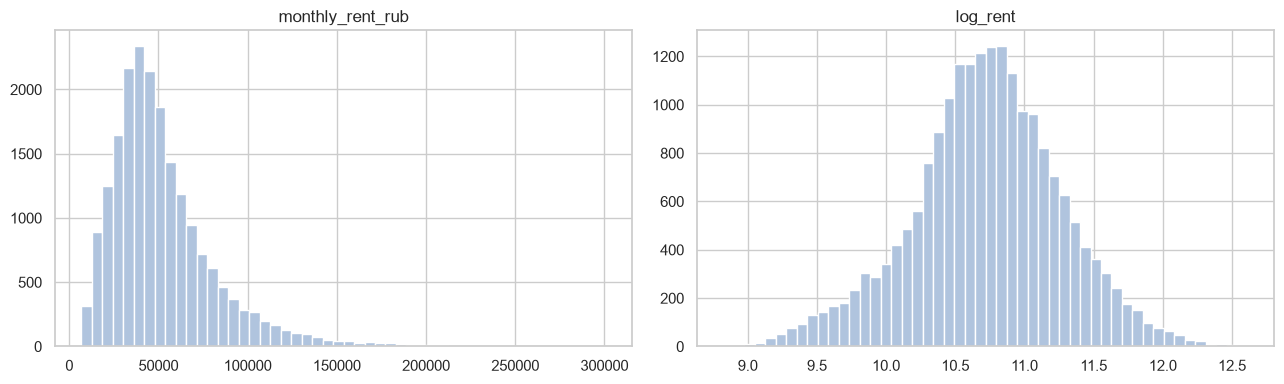

In [42]:
# Target en log (decision del EDA): se conserva el crudo y se agrega log_rent.
df["log_rent"] = np.log1p(df[TARGET])
print(f"skew crudo = {stats.skew(df[TARGET]):.2f} | skew log1p = {stats.skew(df['log_rent']):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, [TARGET, "log_rent"]):
    ax.hist(df[col], bins=50, color="lightsteelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 3. Valores inválidos: reglas de negocio (pre-split)

Cada regla es independiente de la distribución observada (un piso no puede
superar los pisos del edificio; un alquiler no puede ser ≤ 0), por lo que se
aplica sobre las 20.000 filas antes del split. Si una regla se violara: se
corrige cuando la regla determina el valor, se marca con flag cuando es dudosa
y se excluye solo con justificación escrita.

**Resultado real:** 8 de las 9 reglas dan 0, pero 339 avisos (1,7 %) se publicaron antes del `building_year` del edificio (publicados 2021–2023, edificios de 2022–2024). Puede ser alquiler sobre plano/en obra o un error en alguna de las dos fechas. Como la regla no determina qué campo está mal, **se marcan con `flag_invalido` y se conservan**: excluirlas borraría el segmento de edificios nuevos.

In [43]:
anio_pub = df["date_posted"].dt.year
reglas = {
    "floor > total_floors": df["floor"] > df["total_floors"],
    "floor < 1 o total_floors < 1": (df["floor"] < 1) | (df["total_floors"] < 1),
    "total_area <= 0": df["total_area"] <= 0,
    "alquiler <= 0": df[TARGET] <= 0,
    "rooms fuera de 1-4": ~df["rooms"].isin([1, 2, 3, 4]),
    "deposit_months fuera de 0-2": ~df["deposit_months"].isin([0, 1, 2]),
    "building_year implausible o futuro": (df["building_year"] < 1800) | (df["building_year"] > anio_pub),
    "distancias negativas": (df["metro_distance_min"] < 0) | (df["to_center_km"] < 0),
    "lat/lon fuera de Moscu": ~df["lat"].between(55.0, 56.2) | ~df["lon"].between(36.5, 38.0),
}
res = pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="violaciones")
display(res.to_frame())
df["flag_invalido"] = np.logical_or.reduce(list(reglas.values()))
print(f"filas con flag_invalido: {int(df['flag_invalido'].sum())} "
      "(todas por building_year posterior a la publicacion: marcadas, ninguna excluida)")

,violaciones
floor > total_floors,0
floor < 1 o total_floors < 1,0
total_area <= 0,0
alquiler <= 0,0
rooms fuera de 1-4,0
deposit_months fuera de 0-2,0
building_year implausible o futuro,339
distancias negativas,0
lat/lon fuera de Moscu,0


filas con flag_invalido: 339 (todas por building_year posterior a la publicacion: marcadas, ninguna excluida)


## 4. Joins de Fase B reproducidos

Se repiten los joins del EDA con diagnóstico de match y aserción de
cardinalidad: las claves son únicas en ambas tablas, así que el resultado debe
conservar 20.000 filas. Las columnas duplicadas por el join (`okrug` del
mensual, `station_name`, y las coordenadas/antigüedad propias de la estación)
se eliminan o renombran una sola vez, acá.

In [44]:
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro = pd.read_csv(DATA_DIR / "metro_stations.csv")
assert not monthly.duplicated(["district", "year_month"]).any()
assert not metro.duplicated(["station_name"]).any()

n0 = len(df)
enr = df.merge(monthly, on=["district", "year_month"], how="left",
               suffixes=("", "_distmes"), indicator="m1")
print(f"join mensual: {n0:,} -> {len(enr):,} | match={(enr['m1'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m1"]).merge(
    metro, left_on="metro_station", right_on="station_name",
    how="left", suffixes=("", "_metro"), indicator="m2")
print(f"join metro: match={(enr['m2'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m2"])
assert len(enr) == n0, "el join cambio la cantidad de filas"

# Jerarquias: estacion -> 1 linea, distrito -> 1 okrug, y linea consistente con metro_stations.
assert (enr.groupby("metro_station")["metro_line"].nunique() == 1).all()
assert (enr.groupby("district")["okrug"].nunique() == 1).all()
assert (enr["metro_line"] == enr["line"]).all()
enr = enr.drop(columns=["okrug_distmes", "station_name", "line"]).rename(
    columns={"lat_metro": "station_lat", "lon_metro": "station_lon",
             "to_center_km_metro": "station_to_center_km"})
new_cols = [c for c in enr.columns if c not in df.columns]
print(f"columnas nuevas ({len(new_cols)}): {new_cols}")
df = enr

join mensual: 20,000 -> 20,000 | match=100.00%
join metro: match=100.00%
columnas nuevas (14): ['secondary_price_per_sqm', 'newbuild_price_per_sqm', 'rental_price_per_sqm_monthly', 'secondary_mom_change_pct', 'newbuild_mom_change_pct', 'n_listings_secondary', 'n_listings_newbuild', 'n_listings_rental', 'cbr_key_rate_pct', 'avg_mortgage_rate_pct', 'station_lat', 'station_lon', 'year_opened', 'station_to_center_km']


## 5. Valores faltantes: mecanismo antes que receta

La base no trae nulos y —hecho verificado, no asumido— el join tampoco los
introduce: los únicos 129 NaN del mensual son de `2020-01` (primer mes de cada
distrito, sin mes previo para la variación mensual) y los avisos empiezan en
`2021-01`, así que esa suciedad estructural nunca se pega a una fila de alquiler.

In [45]:
miss = pd.DataFrame({"nulos": df.isna().sum(),
                     "pct": (df.isna().mean() * 100).round(3)})
display(miss.sort_values("pct", ascending=False).head(10))
print("nulos totales tras joins:", int(df.isna().sum().sum()))
print("NaN del mensual solo en:", sorted(monthly.loc[monthly["secondary_mom_change_pct"].isna(), "year_month"].unique()),
      "| avisos desde:", df["year_month"].min())

,nulos,pct
id,0,0.0
newbuild_mom_change_pct,0,0.0
year_month,0,0.0
log_rent,0,0.0
flag_invalido,0,0.0
secondary_price_per_sqm,0,0.0
newbuild_price_per_sqm,0,0.0
rental_price_per_sqm_monthly,0,0.0
secondary_mom_change_pct,0,0.0
n_listings_secondary,0,0.0


nulos totales tras joins: 0
NaN del mensual solo en: ['2020-01'] | avisos desde: 2021-01


## 6. Valores atípicos: investigar antes de tocar

Se describen las colas (esto es lectura, no filtrado): alquiler q99 ≈ 161k y
máximo 300.700 RUB frente a una mediana de 45.800; `metro_distance_min` llega
a 966 minutos, implausible a pie. Pueden ser el segmento premium real o
errores de carga, y OLS es sensible a ambos. **Decisión:** conservar todas las
filas, sin winsorizar ni excluir acá; en #8 se agregan flags con umbrales IQR
calculados solo en train, y la branch de modelo hará la sensibilidad
con/sin el top 1 %. Excluir en silencio sesgaría justo el segmento caro.

,mediana,q99,q99.9,max
monthly_rent_rub,45800.0,161102.0,229306.5,300700.0
total_area,53.8,89.2,96.2,104.6
metro_distance_min,103.0,776.0,909.0,966.0
to_center_km,13.2,66.0,68.8,71.1


monthly_rent_rub: fuera de IQR exploratorio = 936 (4.7%)  [solo lectura: el umbral util es el de train, #8]
total_area: fuera de IQR exploratorio = 174 (0.9%)  [solo lectura: el umbral util es el de train, #8]
metro_distance_min: fuera de IQR exploratorio = 1416 (7.1%)  [solo lectura: el umbral util es el de train, #8]
to_center_km: fuera de IQR exploratorio = 1905 (9.5%)  [solo lectura: el umbral util es el de train, #8]


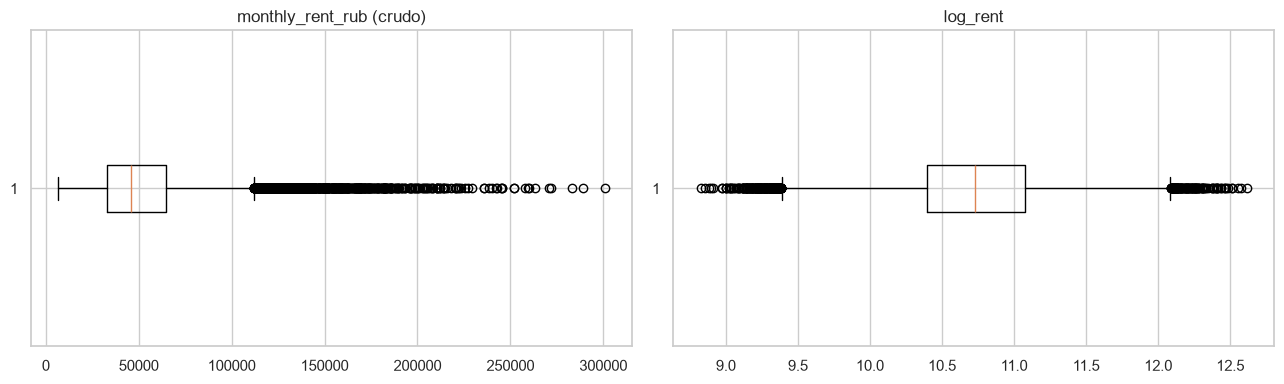

In [46]:
cols_out = [TARGET, "total_area", "metro_distance_min", "to_center_km"]
q = df[cols_out].quantile([0.5, 0.99, 0.999, 1.0]).T.rename(
    columns={0.5: "mediana", 0.99: "q99", 0.999: "q99.9", 1.0: "max"})
display(q.round(1))
for c in cols_out:
    x = df[c]
    lo, hi = x.quantile(0.25) - 1.5 * stats.iqr(x), x.quantile(0.75) + 1.5 * stats.iqr(x)
    print(f"{c}: fuera de IQR exploratorio = {int(((x < lo) | (x > hi)).sum())} "
          f"({((x < lo) | (x > hi)).mean():.1%})  [solo lectura: el umbral util es el de train, #8]")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(df[TARGET], orientation="horizontal"); axes[0].set_title(f"{TARGET} (crudo)")
axes[1].boxplot(df["log_rent"], orientation="horizontal"); axes[1].set_title("log_rent")
plt.tight_layout(); plt.show()

## 7. Identificadores, fuga y duplicación de información

- `id` se conserva solo como clave de trazabilidad; nunca entra como predictor
  (un ID arbitrario no explica un alquiler).
- `rent_per_sqm` **sale** del dataset limpio: es `monthly_rent_rub / total_area`
  (r = 0,89 con el target). Dejarla sería fuga directa.
- `rental_price_per_sqm_monthly` (promedio distrital del mes) se conserva pero
  queda **marcada**: es contexto agregado legítimo, aunque cercano al target;
  la branch de modelo debe discutir su fuga antes de usarla.
- Pares colineales del EDA (distancia al metro ↔ al centro 0,90; superficie ↔
  ambientes 0,88; lat/lon ↔ distancia al centro ≈ −0,71) y redundancias del
  join (coordenadas de la estación vs. del aviso): se documentan acá y se
  resuelven una sola vez al modelar (elegir una por par o regularizar), no dos
  veces.

In [47]:
chk = (df["rent_per_sqm"] - df[TARGET] / df["total_area"]).abs().max()
print(f"max |rent_per_sqm - alquiler/superficie| = {chk:.2f} (redondeo) -> deriva del target")
clean = df.drop(columns=["rent_per_sqm"]).copy()
FEATURES_PROHIBIDAS = ["id", "rent_per_sqm"]
FEATURES_MARCADAS = ["rental_price_per_sqm_monthly"]
print("fuera por fuga:", FEATURES_PROHIBIDAS, "| marcadas:", FEATURES_MARCADAS)
print(f"clean: {clean.shape[0]:,} filas x {clean.shape[1]} columnas")

max |rent_per_sqm - alquiler/superficie| = 2.09 (redondeo) -> deriva del target
fuera por fuga: ['id', 'rent_per_sqm'] | marcadas: ['rental_price_per_sqm_monthly']
clean: 20,000 filas x 38 columnas


## 8. Split primero; parámetros aprendidos, solo en train

Recién acá se divide (80/20, estratificado por `okrug`, semilla fija). Todo lo
anterior fue regla de negocio; todo lo siguiente se ajusta con train:

1. **Imputación:** `SimpleImputer(strategy="median")` ajustado en train. Hoy no
   hay huecos, así que no cambia valores — pero la verificación de abajo prueba
   que la mediana usada es la de train y no la global.
2. **Atípicos:** umbrales IQR por columna calculados en train y aplicados como
   flags a train y test (sin excluir filas).
3. **Codificación:** one-hot ajustado en train con `handle_unknown="ignore"`.
   Para OLS con constante se usan k−1 dummies (la categoría mayoritaria como
   base) y así se evita la trampa dummy. Las categóricas de
   alta cardinalidad (`district` 129, `metro_station` 104) se dejan marcadas
   para que el modelo decida agruparlas.

In [48]:
train, test = train_test_split(clean, test_size=0.20, random_state=SEED,
                               stratify=clean["okrug"])
print(f"train {len(train):,} | test {len(test):,} | sin solape de id:",
      train["id"].is_unique and test["id"].is_unique
      and set(train["id"]).isdisjoint(test["id"]))

num_demo = [TARGET, "total_area", "metro_distance_min"]
imp = SimpleImputer(strategy="median").fit(train[num_demo])
med_train = pd.Series(imp.statistics_, index=num_demo)
med_global = clean[num_demo].median()
display(pd.DataFrame({"mediana_train (usada)": med_train, "mediana_global (prohibida)": med_global}).round(2))
assert np.allclose(imp.statistics_, train[num_demo].median().to_numpy())
assert not np.allclose(imp.statistics_, med_global.to_numpy())
print("OK: el imputador aprendio de train, no del dataset completo (hoy sin huecos: no altera valores).")

def iqr_flags(base, ref):
    flags = pd.DataFrame(index=base.index)
    for c in ["total_area", "metro_distance_min", "to_center_km", TARGET]:
        x = ref[c]
        lo = x.quantile(0.25) - 1.5 * stats.iqr(x)
        hi = x.quantile(0.75) + 1.5 * stats.iqr(x)
        flags[f"flag_outlier_{c}"] = ((base[c] < lo) | (base[c] > hi)).astype("int8")
    return flags

train_out = pd.concat([train, iqr_flags(train, train)], axis=1)
test_out = pd.concat([test, iqr_flags(test, train)], axis=1)
print("flags en test (umbrales de train):")
display(test_out[[c for c in test_out if c.startswith("flag_outlier")]].sum().rename("filas").to_frame())

cats_modelo = ["rooms", "building_type", "renovation", "okrug", "metro_line"]
enc = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)
enc.fit(train[cats_modelo])
print(f"one-hot (k-1, base=mayoritaria) ajustado en train: {enc.transform(train[cats_modelo]).shape[1]} columnas "
      f"desde {cats_modelo}; district/metro_station quedan para decision del modelo")

train 16,000 | test 4,000 | sin solape de id: True


,mediana_train (usada),mediana_global (prohibida)
monthly_rent_rub,45900.0,45800.0
total_area,53.8,53.8
metro_distance_min,103.0,103.0


OK: el imputador aprendio de train, no del dataset completo (hoy sin huecos: no altera valores).
flags en test (umbrales de train):


,filas
flag_outlier_total_area,37
flag_outlier_metro_distance_min,275
flag_outlier_to_center_km,387
flag_outlier_monthly_rent_rub,193


one-hot (k-1, base=mayoritaria) ajustado en train: 32 columnas desde ['rooms', 'building_type', 'renovation', 'okrug', 'metro_line']; district/metro_station quedan para decision del modelo


## 9. Guardado y resumen de transformaciones

Se guardan tres artefactos en `data/processed/`: la base limpia pre-split
(reglas de negocio aplicadas, sin `rent_per_sqm`) y el par train/test ya
dividido con flags de atípicos de train. Los crudos de `data/` no se modifican.

In [49]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUT_DIR / "rentals_clean.csv", index=False)
train_out.to_csv(OUT_DIR / "rentals_train.csv", index=False)
test_out.to_csv(OUT_DIR / "rentals_test.csv", index=False)
for f in ["rentals_clean.csv", "rentals_train.csv", "rentals_test.csv"]:
    d = pd.read_csv(OUT_DIR / f)
    print(f"{f}: {d.shape[0]:,} x {d.shape[1]} | rent_per_sqm presente: {'rent_per_sqm' in d.columns}")

rentals_clean.csv: 20,000 x 38 | rent_per_sqm presente: False
rentals_train.csv: 16,000 x 42 | rent_per_sqm presente: False
rentals_test.csv: 4,000 x 42 | rent_per_sqm presente: False
